In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from scipy.stats import multivariate_normal

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
X, y = make_blobs(
    n_samples=300,
    centers=3,
    n_features=2,
    cluster_std=1.5,
    random_state=42
)

print("Dataset generated successfully!")
print("Dataset shape:", X.shape)
print("Number of samples:", len(X))
print("Number of features:", X.shape[1])

Dataset generated successfully!
Dataset shape: (300, 2)
Number of samples: 300
Number of features: 2


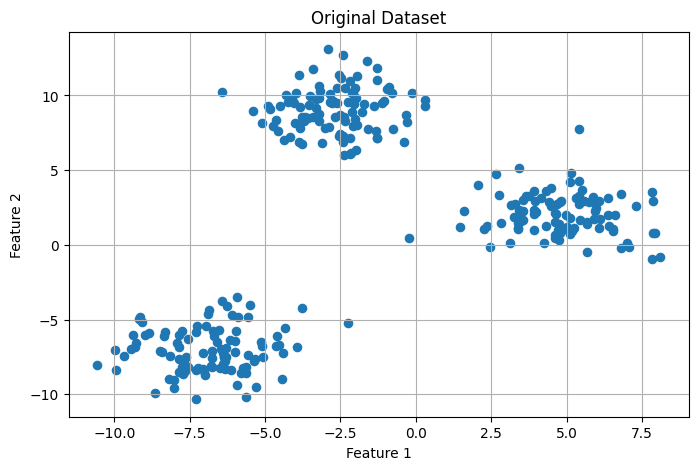

In [3]:
plt.figure(figsize=(8, 5))

plt.scatter(X[:, 0], X[:, 1], s=35)

plt.title("Original Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(True)

plt.show()

In [4]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Data preprocessing completed!")
print("Scaled dataset shape:", X_scaled.shape)


Data preprocessing completed!
Scaled dataset shape: (300, 2)


In [5]:
n_components = 3

np.random.seed(42)

n_samples, n_features = X_scaled.shape

# Initialize cluster means using random data points
random_indices = np.random.choice(
    n_samples,
    n_components,
    replace=False
)

means = X_scaled[random_indices]

# Initialize covariance matrices
covariances = np.array([
    np.eye(n_features) for _ in range(n_components)
])

# Initialize equal weights
weights = np.ones(n_components) / n_components

print("GMM initialized successfully!")
print("Initial Means:\n", means)
print("Initial Weights:", weights)

GMM initialized successfully!
Initial Means:
 [[ 1.05919047  0.28118806]
 [-1.01094344 -1.10560476]
 [ 1.31769149 -0.04615889]]
Initial Weights: [0.33333333 0.33333333 0.33333333]


In [6]:
from scipy.special import logsumexp

def expectation_step(X, means, covariances, weights):

    n_samples = X.shape[0]
    n_components = len(weights)

    log_prob = np.zeros((n_samples, n_components))

    for k in range(n_components):

        log_prob[:, k] = (
            np.log(weights[k]) +
            multivariate_normal.logpdf(
                X,
                mean=means[k],
                cov=covariances[k]
            )
        )

    log_likelihood = logsumexp(log_prob, axis=1)

    responsibilities = np.exp(
        log_prob - log_likelihood[:, np.newaxis]
    )

    return responsibilities, np.sum(log_likelihood)


print("E-step function created successfully!")

E-step function created successfully!


In [7]:
def maximization_step(X, responsibilities):

    n_samples, n_features = X.shape
    n_components = responsibilities.shape[1]

    Nk = responsibilities.sum(axis=0)

    # Update weights
    weights = Nk / n_samples

    # Update means
    means = (
        responsibilities.T @ X
    ) / Nk[:, np.newaxis]

    # Update covariance matrices
    covariances = []

    for k in range(n_components):

        diff = X - means[k]

        cov = (
            (responsibilities[:, k][:, np.newaxis] * diff).T
            @ diff
        ) / Nk[k]

        cov += np.eye(n_features) * 1e-6

        covariances.append(cov)

    return means, np.array(covariances), weights


print("M-step function created successfully!")

M-step function created successfully!


In [8]:
max_iterations = 100
tolerance = 1e-4

log_likelihood_history = []

previous_log_likelihood = None

for iteration in range(max_iterations):

    # E-step
    responsibilities, log_likelihood = expectation_step(
        X_scaled,
        means,
        covariances,
        weights
    )

    # M-step
    means, covariances, weights = maximization_step(
        X_scaled,
        responsibilities
    )

    log_likelihood_history.append(log_likelihood)

    # Check convergence
    if previous_log_likelihood is not None:

        difference = abs(
            log_likelihood - previous_log_likelihood
        )

        if difference < tolerance:
            print("Algorithm converged!")
            break

    previous_log_likelihood = log_likelihood

print("EM Algorithm completed!")
print("Iterations:", iteration + 1)
print("Final Log Likelihood:", log_likelihood_history[-1])

Algorithm converged!
EM Algorithm completed!
Iterations: 25
Final Log Likelihood: -345.3039297218468


In [9]:
responsibilities, final_log_likelihood = expectation_step(
    X_scaled,
    means,
    covariances,
    weights
)

labels = np.argmax(responsibilities, axis=1)

print("Cluster assignments completed!")
print("First 20 assignments:")
print(labels[:20])

print("Number of points in each cluster:")
print(np.bincount(labels, minlength=3))

Cluster assignments completed!
First 20 assignments:
[1 1 0 2 1 2 0 2 0 0 0 2 0 0 1 0 1 2 0 0]
Number of points in each cluster:
[100 100 100]


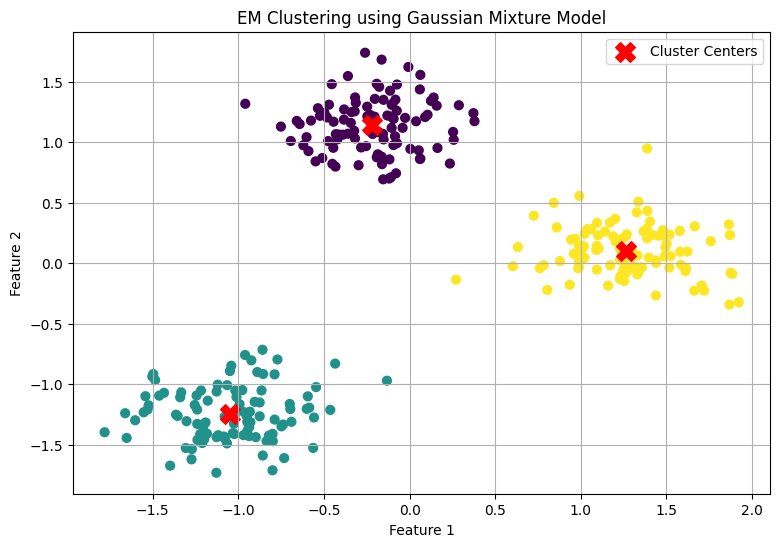

In [10]:
plt.figure(figsize=(9, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=labels,
    cmap='viridis',
    s=40
)

plt.scatter(
    means[:, 0],
    means[:, 1],
    marker='X',
    s=200,
    c='red',
    label='Cluster Centers'
)

plt.title("EM Clustering using Gaussian Mixture Model")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)

plt.show()

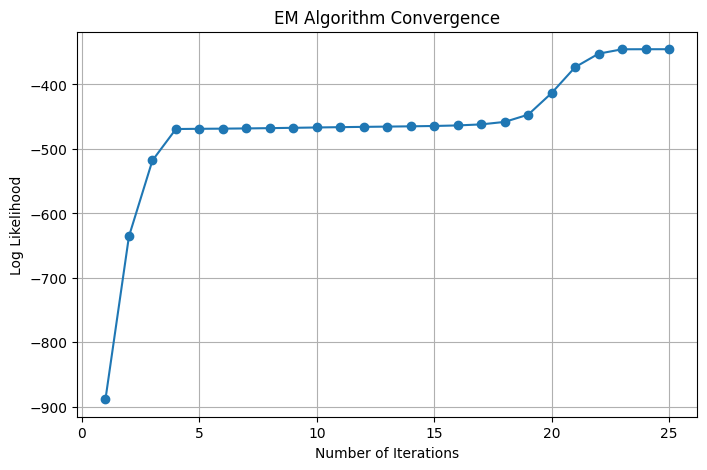

In [11]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(log_likelihood_history) + 1),
    log_likelihood_history,
    marker='o'
)

plt.title("EM Algorithm Convergence")
plt.xlabel("Number of Iterations")
plt.ylabel("Log Likelihood")
plt.grid(True)

plt.show()

In [12]:
score = silhouette_score(X_scaled, labels)

print("Clustering Evaluation")
print("---------------------")
print("Silhouette Score:", round(score, 4))
print("Number of Clusters:", len(np.unique(labels)))
print("Total Data Points:", len(X_scaled))
print("Algorithm Converged:", iteration + 1 < max_iterations or difference < tolerance)

Clustering Evaluation
---------------------
Silhouette Score: 0.7734
Number of Clusters: 3
Total Data Points: 300
Algorithm Converged: True


In [13]:
print("FINAL GMM RESULTS")
print("=================")

for k in range(n_components):

    print("\nCluster:", k + 1)
    print("Mean:", means[k])
    print("Covariance Matrix:\n", covariances[k])
    print("Weight:", round(weights[k], 4))

print("\nTotal Iterations:", iteration + 1)
print("Final Log Likelihood:", final_log_likelihood)
print("Silhouette Score:", round(score, 4))

FINAL GMM RESULTS

Cluster: 1
Mean: [-0.21814972  1.14246839]
Covariance Matrix:
 [[0.06604516 0.00288476]
 [0.00288476 0.04879953]]
Weight: 0.3333

Cluster: 2
Mean: [-1.04793261 -1.24307862]
Covariance Matrix:
 [[0.0908261  0.00632227]
 [0.00632227 0.04858301]]
Weight: 0.3333

Cluster: 3
Mean: [1.2660778  0.10061344]
Covariance Matrix:
 [[ 0.09442184 -0.00650352]
 [-0.00650352  0.0420229 ]]
Weight: 0.3333

Total Iterations: 25
Final Log Likelihood: -345.3039297218544
Silhouette Score: 0.7734
